# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [1]:
print ("Hello, Artificial Intelignce!")

Hello, Artificial Intelignce!


*Twoja odpowiedź:*
Hello

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [2]:
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
print(s1)

s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
print(s2)

Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [3]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [4]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]

mean_acc = sum(acc)/len(acc)
std_acc = (sum((x-mean_acc)**2 for x in acc)/len(acc))**0.5

print ("Mean acc: " + str(mean_acc))
print ("Std acc: " + str(std_acc))

Mean acc: 0.8425
Std acc: 0.05309190145398825


In [5]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*
Odchylenie standardowe informuje nas jak bardzo dane wzbiorze różnia się od wartości średniej. W kontekście tych czterech modeli mamy niskie odchylenie standardowe, około 0.053, co dla średniej 0.8425 oznacza około 6% odchylenia. Oznacza to, że dane są mocno skupione wokół średniej.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [6]:
# Twoje rozwiązanie

text = "AI systems learn from data. AI systems make predictions from data"

counts = {}
for word in text.replace(".","").lower().split():
    if word in counts:
        counts[word] += 1
    else:
        counts[word] = 1

most_common = [word for word, count in counts.items() if count == max(counts.values())]
print(most_common)

['ai', 'systems', 'from', 'data']


In [7]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [8]:
# Twoje rozwiązanie
def performance_label(score):
    if not (0 <= score <= 1):
        raise ValueError
    elif score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    elif score > 0.90:
        return "strong"
    else:
        raise TypeError

scores = [0.72, 0.81, 0.93, 0.88]
not_weak_scores = [score for score in scores if performance_label(score) != "weak"]
mean_ok = sum(not_weak_scores)/len(not_weak_scores)
print(mean_ok)

0.8733333333333334


In [9]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [10]:
# Twoje rozwiązanie
def print_ranking(results):
    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)

    for i, (model, score) in enumerate(sorted_results):
        print(f"{i+1}. {model} – {score}")

    best_model = sorted_results[0][0]
    print(f"Najlepszy model: {best_model} – rekomendowany do wdrożenia")
    return best_model

results = {"SVM": 0.81, "DecisionTree": 0.74, "NeuralNet": 0.92}
results["Transformer"] = 0.95

mean_results = sum(results.values())/len(results)
above_mean = [model for model, score in results.items() if score > mean_results]

print_ranking(results)

1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia


'Transformer'

In [11]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [12]:
# Twoje rozwiązanie
def clean_scores(raw):
    valid = [score for score in raw if isinstance(score, (int, float)) and 0 <= score <= 1]
    n_invalid = len(raw) - len(valid)

    return valid, n_invalid

raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]

valid, n_invalid = clean_scores(raw)
print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {sum(valid)/len(valid)}")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334


In [13]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [14]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [15]:
# Twoje rozwiązanie
def summarize_model(info):
    print(info["name"])

    mean_score = sum(info["metrics"].values())/len(info["metrics"])
    print(mean_score)

    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")

    info["mean_score"] = mean_score
    return info

model_info = summarize_model(model_info)

NeuralNet
0.88
Model wymaga poprawy


In [16]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

X
0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [17]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [18]:
# Twoje rozwiązanie

TP = 0
FP = 0
FN = 0
TN = 0

for (y_t, y_p) in zip(y_true, y_pred):
    if y_t == 1 and y_p == 1:
        TP += 1
    elif y_t == 1 and y_p == 0:
        FN += 1
    elif y_t == 0 and y_p == 1:
        FP += 1
    elif y_t == 0 and y_p == 0:
        TN += 1

precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)

In [19]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [20]:
import numpy as np

# Twoje rozwiązanie

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    TN = np.sum((y_true == 0) & (y_pred == 0))

    accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) != 0 else 0.0
    precision = TP / (TP + FP) if (TP + FP) != 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) != 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) != 0 else 0.0

    metryki = {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

    return metryki

In [21]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [22]:
# Twoje rozwiązanie
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

confusion_matrix = confusion_matrix(y_true, y_pred, labels=[1, 0])
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

np.isclose(binary_metrics(y_true, y_pred)["TP"], confusion_matrix[0, 0])
np.isclose(binary_metrics(y_true, y_pred)["FP"], confusion_matrix[0, 1])
np.isclose(binary_metrics(y_true, y_pred)["FN"], confusion_matrix[1, 0])
np.isclose(binary_metrics(y_true, y_pred)["TN"], confusion_matrix[1, 1])

# confusion_matrix() zwraca macierz pomyłek w układzie, w którym element w i-tym wierszu i j-tej kolumnie
# wskazuje liczbę próbek o rzeczywistej klasie i oraz przewidzianej klasie j. Domyślnie sckit-learn sortuje
# klasy rosnąco

np.True_

---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*
accuracy dla zawsze-zero wyniesie 0.95;
accuracy dla zaszumiony wyniesie około 0.9;

zawsze-zero będzie miał wyższa accuracy;

precision dla zaszumiony będzei bliżej 0.3;

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [23]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [24]:
import pandas as pd

y_true, y_zero, y_noisy = make_data(0.05)

metryki = {}

metryki["zeros"] = binary_metrics(y_true, y_zero)
print("Metryki zawsze-zero:", metryki["zeros"])

metryki["noisy"] = binary_metrics(y_true, y_noisy)
print("Metryki zaszumiony:", metryki["noisy"])

ps = [0.5, 0.3, 0.1, 0.05, 0.01]

records = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p)

    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)

    records.append({
        "p": p,
        "model": "zawsze-zero",
        "accuracy": m_zero["accuracy"],
        "precision": m_zero["precision"],
        "recall": m_zero["recall"],
        "f1": m_zero["f1"]
    })

    records.append({
        "p": p,
        "model": "zaszumiony",
        "accuracy": m_noisy["accuracy"],
        "precision": m_noisy["precision"],
        "recall": m_noisy["recall"],
        "f1": m_noisy["f1"]
    })

df = pd.DataFrame(records)
print(df)

Metryki zawsze-zero: {'TP': np.int64(0), 'FP': np.int64(0), 'FN': np.int64(508), 'TN': np.int64(9492), 'accuracy': np.float64(0.9492), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}
Metryki zaszumiony: {'TP': np.int64(470), 'FP': np.int64(926), 'FN': np.int64(38), 'TN': np.int64(8566), 'accuracy': np.float64(0.9036), 'precision': np.float64(0.336676217765043), 'recall': np.float64(0.9251968503937008), 'f1': np.float64(0.49369747899159666)}
      p        model  accuracy  precision    recall        f1
0  0.50  zawsze-zero    0.4985   0.000000  0.000000  0.000000
1  0.50   zaszumiony    0.9036   0.902284  0.905882  0.904080
2  0.30  zawsze-zero    0.6957   0.000000  0.000000  0.000000
3  0.30   zaszumiony    0.9036   0.802268  0.906671  0.851280
4  0.10  zawsze-zero    0.9016   0.000000  0.000000  0.000000
5  0.10   zaszumiony    0.9036   0.505663  0.907520  0.649455
6  0.05  zawsze-zero    0.9492   0.000000  0.000000  0.000000
7  0.05   zaszumiony    0.9036   0.336676  0.925197

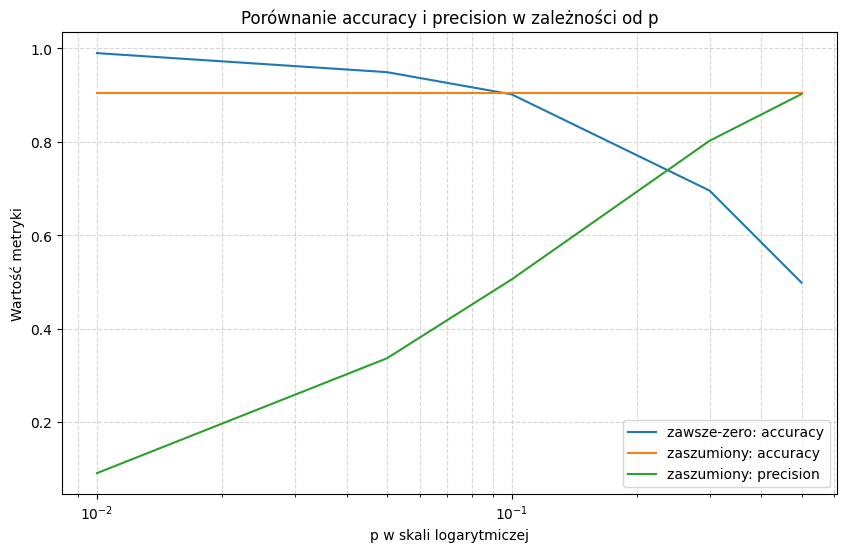

In [25]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot()

x = df['p'].unique()

ax.set_xscale("log")

y = (
    df[df['model'] == 'zawsze-zero']['accuracy'],
    df[df['model'] == 'zaszumiony']['accuracy'],
    df[df['model'] == 'zaszumiony']['precision']
)

ax.set_ylabel('Wartość metryki')
ax.set_xlabel('p w skali logarytmiczej')
ax.set_title('Porównanie accuracy i precision w zależności od p')

ax.plot(x, y[0], label='zawsze-zero: accuracy')
ax.plot(x, y[1], label='zaszumiony: accuracy')
ax.plot(x, y[2], label='zaszumiony: precision')

ax.legend()
ax.grid(True, which="both", linestyle="--", alpha=0.5)


plt.show()

In [26]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*
1. Tak przewidywania się potwierdziły. Dla małych p otrzymujemy wysoką accuracy dla modelu zero, która spada dla dużych p. Tak jak przewidywano dokładnośc modelu zawsze zero zależy od danych wejściowych. Zaskoczył wzrost precyzji modelu zaszumionego dla większych p.
2. Wyższą accuracy ma model zawsze zero, jednak bardziej użyteczny jest model zaszumiony ponieważ pomimo faktu że może błędnie przypisać prawdę do fałszu, co w tym przypadku głównie obniża jego accuracy w stosunku do zawsze zero, to daje on wysoką szansę na wykrycie przypadku prawdy.
3. Ponieważ wraz ze wzrostem liczby pozytywnych wyników, większe p, spada liczba niepoprawnych predykcji prawd, false positive, a wzrasta liczba niepoprawnych predykcji fałszy, false negative, co biorąc pod uwagę wzór na precision, TP/(TP + FP), oznacza zwiększenie precision.
4. Zaraportuje metrykę FN jako główną. Konsekwencją błędów FP będzie oznaczenie osoby jako chorej pomimo braku choroby. Błąd FN wskazuje brak choroby przy jej występowaniu, co chcemy możliwie jak najskuteczniej wykluczyć.

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [27]:
# Twoje rozwiązanie
